(mmm_prior_reweighting)=
# Reweighting Priors Instead of Refitting

Fit the model **once**, then reweight the saved posterior draws to see what a *different prior* would give. Pareto k̂ and the effective sample size (ESS) say when to trust the result and when to refit.

This notebook uses the model and data of {ref}`mmm_prior_sensitivity`. That notebook asks *which* priors the posterior is sensitive to. This one asks *what the posterior becomes* under a specific alternative, for example stakeholders expecting an x1 ROAS of 140 instead of 100. Changes to the likelihood are in {ref}`mmm_likelihood_reweighting`.

The notebook runs in about 1.5 minutes on 6 CPU cores, nearly all of it in the fits (about 15 seconds each):

1. Fit the model once (the reference fit).
2. Reweight to a new business prior and check it against a full refit.
3. Sweep several priors with no refits.
4. A case where reweighting cannot help.
5. How this relates to power-scaling.

**How it works.** Each draw gets the weight `new prior density / reference prior density`. If the new prior favours regions where the reference draws are rare, a few draws carry all the weight and the answer is unreliable. Pareto-smoothing the weights (PSIS) estimates this: k̂ is the tail index of the weights and the ESS counts the draws that still contribute.

| Pareto k̂ | verdict |
|---|---|
| < 0.5 | use the reweighted posterior |
| 0.5 – 0.7 | refit if the number feeds a decision |
| ≥ 0.7 | refit |

The verdict is also **refit** when the ESS is below 100 draws, whatever k̂ says: a change that only removes draws leaves no tail for k̂ to measure. The ESS accounts for the autocorrelation of the chains (it is scaled by `r_eff`).

## Prepare Notebook

In [1]:
%config InlineBackend.figure_format = "retina"

import logging
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
from arviz_stats.base import array_stats
from IPython.display import display
from pymc_extras.prior import Prior
from scipy import stats

from pymc_marketing.hsgp_kwargs import HSGPKwargs
from pymc_marketing.mmm import MMM, GeometricAdstock, LogisticSaturation
from pymc_marketing.mmm.reweighting import psis_reweight, relative_efficiency
from pymc_marketing.paths import data_dir

warnings.filterwarnings("ignore")
logging.getLogger("pymc").setLevel(
    logging.WARNING
)  # keep sampler warnings, drop the start-up message
az.style.use("arviz-darkgrid")
plt.rcParams["figure.figsize"] = [12, 7]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"

## Data and Reference Fit

The data are the weekly spend of two media channels, `x1` and `x2`, and the target `y`.

In [2]:
raw_df = pd.read_csv(data_dir / "mmm_roas_data.csv", parse_dates=["date"])
X = raw_df[["date", "x1", "x2"]]
y = raw_df["y"]
channel_columns = ["x1", "x2"]

The model is the one of the sensitivity notebook. The business prior expects ROAS 100 ± 20 for `x1` and 150 ± 50 for `x2`.

In [3]:
# The model of the sensitivity notebook: weakly informative media priors, HSGP baseline, yearly seasonality.
baseline_model_config = {
    "likelihood": Prior("Normal", sigma=Prior("HalfNormal", sigma=0.5)),
    "gamma_fourier": Prior("Normal", mu=0, sigma=2, dims="fourier_mode"),
    "intercept_tvp_config": HSGPKwargs(
        m=50, L=None, eta_lam=1.0, ls_mu=5.0, ls_sigma=10.0, cov_func=None
    ),
    "adstock_alpha": Prior("Beta", alpha=2, beta=3, dims="channel"),
    "saturation_lam": Prior("Gamma", alpha=2, beta=2, dims="channel"),
    "saturation_beta": Prior("HalfNormal", sigma=1, dims="channel"),
}
# Business prior: ROAS target and sigma per channel.
reference_business = {"roas": [100.0, 150.0], "sigma": [20.0, 50.0]}

sampler_config = {
    "tune": 1_000,
    "chains": 6,
    "cores": 6,
    "draws": 2_000,
    "progressbar": False,
    "nuts": {"adaptation": "draw_diag", "target_accept": 0.94},
}

`fit` builds, fits and post-processes the model. `spec` lists what differs from the reference, which lets the same function refit any alternative below.

In [ ]:
def prior_density(key, value):
    """Return the SciPy density of a prior of the spec; same numbers as the Prior handed to the refit."""
    return {
        "sat_beta": lambda v: stats.halfnorm(scale=v),
        "adstock": lambda v: stats.beta(*v),
    }[key](value)


def fit(seed, spec=None, logp=False):
    """Fit the model; `spec` lists what differs from the reference (see log_ratio)."""
    spec = spec or {}
    config = dict(baseline_model_config)
    if "sat_beta" in spec:
        config["saturation_beta"] = Prior(
            "HalfNormal", sigma=spec["sat_beta"], dims="channel"
        )
    if "adstock" in spec:
        config["adstock_alpha"] = Prior(
            "Beta", alpha=spec["adstock"][0], beta=spec["adstock"][1], dims="channel"
        )
    mmm = MMM(
        adstock=GeometricAdstock(l_max=4),
        saturation=LogisticSaturation(),
        date_column="date",
        channel_columns=channel_columns,
        target_column="y",
        time_varying_intercept=True,
        time_varying_media=False,
        yearly_seasonality=5,
        model_config=config,
    )
    mmm.build_model(X, y)
    mmm.add_original_scale_contribution_variable(
        var=["channel_contribution", "fourier_contribution", "intercept_contribution"]
    )
    business = spec.get("business", reference_business)
    if business != "none":
        mmm.add_cost_per_target_calibration(
            data=X,
            calibration_data=pd.DataFrame({"channel": channel_columns, **business}),
            name_prefix="business_prior",
            target_column="roas",
            target_per_cost=True,
        )
    mmm.fit(X, y, random_seed=np.random.default_rng(seed), **sampler_config)
    mmm.idata["posterior"]["ROAS"] = (
        mmm.incrementality.compute_incremental_contribution("all_time")
        / mmm.idata["constant_data"]["channel_data"].sum("date")
    )
    if logp:  # log densities, only needed for the power-scaling comparison at the end
        with mmm.model:
            pm.compute_log_likelihood(mmm.idata)
            pm.stats.compute_log_prior(mmm.idata)
        # The business prior is coded as an observed Normal. It is a prior, not data: move it to log_prior.
        mmm.idata["log_prior"]["business_prior"] = mmm.idata["log_likelihood"][
            "business_prior"
        ]
        del mmm.idata["log_likelihood"]["business_prior"]
    return mmm


def log_ratio(spec, mmm):
    """Return log(new / reference) per draw, from the saved draws of the reference fit `mmm`.

    The spec keys are `business` ({"roas": [x1, x2], "sigma": [x1, x2]} or "none"), `sat_beta` (HalfNormal scale
    of `saturation_beta`) and `adstock` (Beta(a, b) of `adstock_alpha`). Terms that do not change cancel and are
    left out.
    """
    total = 0.0
    if (
        "business" in spec
    ):  # the business prior is an observed Normal on the model's ROAS
        roas = draws(mmm, "ROAS")
        old = stats.norm.logpdf(
            reference_business["roas"], roas, reference_business["sigma"]
        ).sum(1)
        if spec["business"] == "none":
            new = 0.0
        else:
            new = stats.norm.logpdf(
                spec["business"]["roas"], roas, spec["business"]["sigma"]
            ).sum(1)
        total = total + new - old
    for key, name, ref_value in (
        ("sat_beta", "saturation_beta", 1.0),
        ("adstock", "adstock_alpha", [2.0, 3.0]),
    ):
        if key in spec:
            x = draws(mmm, name)
            total = total + (
                prior_density(key, spec[key]).logpdf(x)
                - prior_density(key, ref_value).logpdf(x)
            ).sum(1)
    return total

The reweighting itself is two functions of `pymc_marketing.mmm.reweighting`: `psis_reweight` smooths the weights and reports k̂, the ESS and a verdict, and `relative_efficiency` measures how well the reference chains mix. `draws` extracts the draws of a variable.

In [5]:
def draws(mmm, name):
    """Posterior draws of `name` with chains and draws merged, shape (n_draws, ...)."""
    return (
        mmm.idata["posterior"][name]
        .stack(s=("chain", "draw"))
        .transpose("s", ...)
        .values
    )

In [6]:
def plot_roas(roas, w, refit=None, title=""):
    """Plot ROAS per channel: reference posterior, reweighted posterior and (optionally) the full refit."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), layout="constrained")
    for j, ax in enumerate(axes):
        lo, hi = np.quantile(roas[:, j], [0.001, 0.999])
        if refit is not None:
            lo, hi = (
                min(lo, refit[:, j].min()),
                max(hi, np.quantile(refit[:, j], 0.999)),
            )
        bins = np.linspace(lo, hi, 50)
        ax.hist(
            roas[:, j],
            bins,
            density=True,
            histtype="step",
            color="0.55",
            lw=1.5,
            label="reference fit",
        )
        ax.hist(
            roas[:, j],
            bins,
            weights=w,
            density=True,
            histtype="step",
            color="C0",
            lw=2,
            label="reweighted",
        )
        if refit is not None:
            ax.hist(
                refit[:, j],
                bins,
                density=True,
                histtype="step",
                color="k",
                lw=1.5,
                ls="--",
                label="full refit",
            )
        ax.set(title=f"ROAS {channel_columns[j]}", yticks=[])
    axes[0].legend(frameon=False)
    fig.suptitle(title, fontweight="bold")
    return fig


def compare(roas, w, refit=None):
    """Posterior mean and SD of ROAS: reference, reweighted, refit; error in refit SDs."""
    rows = []
    for j, channel in enumerate(channel_columns):
        mean = np.sum(w * roas[:, j])
        row = {
            "channel": channel,
            "reference": roas[:, j].mean(),
            "reweighted": mean,
            "reweighted sd": np.sqrt(np.sum(w * (roas[:, j] - mean) ** 2)),
        }
        if refit is not None:
            row |= {
                "refit": refit[:, j].mean(),
                "refit sd": refit[:, j].std(),
                "|reweighted - refit| / refit sd": abs(mean - refit[:, j].mean())
                / refit[:, j].std(),
            }
        rows.append(row)
    return pd.DataFrame(rows).set_index("channel").round(2)

The one expensive step. In real use this is your normal fit.

In [7]:
ref = fit(seed=1, logp=True)

Output()

Output()

Output()

In [8]:
roas = draws(ref, "ROAS")
r_eff = relative_efficiency(
    ref.idata["posterior"],
    ["ROAS", "adstock_alpha", "saturation_lam", "saturation_beta", "y_sigma"],
)
print(f"relative MCMC efficiency {r_eff:.2f}")
print(f"ROAS mean {roas.mean(0).round(1)}, sd {roas.std(0).round(1)}")

relative MCMC efficiency 1.00
ROAS mean [170.9 143.4], sd [ 9.8 11. ]


In [9]:
# Warm-up: the first call pays one-off start-up costs, so the timings below show the reweighting itself.
_ = psis_reweight(
    log_ratio({"business": {"roas": [140.0, 150.0], "sigma": [20.0, 50.0]}}, ref), r_eff
)

The data say x1 ROAS is about 170, well above the business prior of 100: the prior pulls the estimate down. What would a prior centred at 140 do?

## A New Business Prior, Checked Against a Full Refit

`log_ratio` turns the change into one log weight per draw. The refit (dashed) is only here to check the answer. Refits with different seeds differ a little too, so compare `|reweighted - refit|` with that noise (about 0.01 SD in the evidence below), not with zero.

In [10]:
def try_spec(label, spec, seed, refit=True):
    """Reweight the reference draws to `spec`; optionally refit to check the answer."""
    start = time.perf_counter()
    result = psis_reweight(log_ratio(spec, ref), r_eff)
    print(label)
    print(
        f"reweighting took {time.perf_counter() - start:.3f} s: k-hat = {result.pareto_k:.2f}, "
        f"ESS = {100 * result.ess_fraction:.0f}% of the draws -> {result.verdict.upper()}"
    )
    refit_mmm, refit_roas = None, None
    if refit:
        start = time.perf_counter()
        refit_mmm = fit(seed, spec)
        refit_roas = draws(refit_mmm, "ROAS")
        print(f"full refit took {time.perf_counter() - start:.0f} s")
    plot_roas(roas, result.weights, refit_roas, title=label)
    plt.show()
    display(compare(roas, result.weights, refit_roas))
    return result, refit_mmm

Business prior x1: ROAS 140 ± 20 (reference 100 ± 20)
reweighting took 0.003 s: k-hat = 0.24, ESS = 36% of the draws -> USE IT


Output()

full refit took 16 s


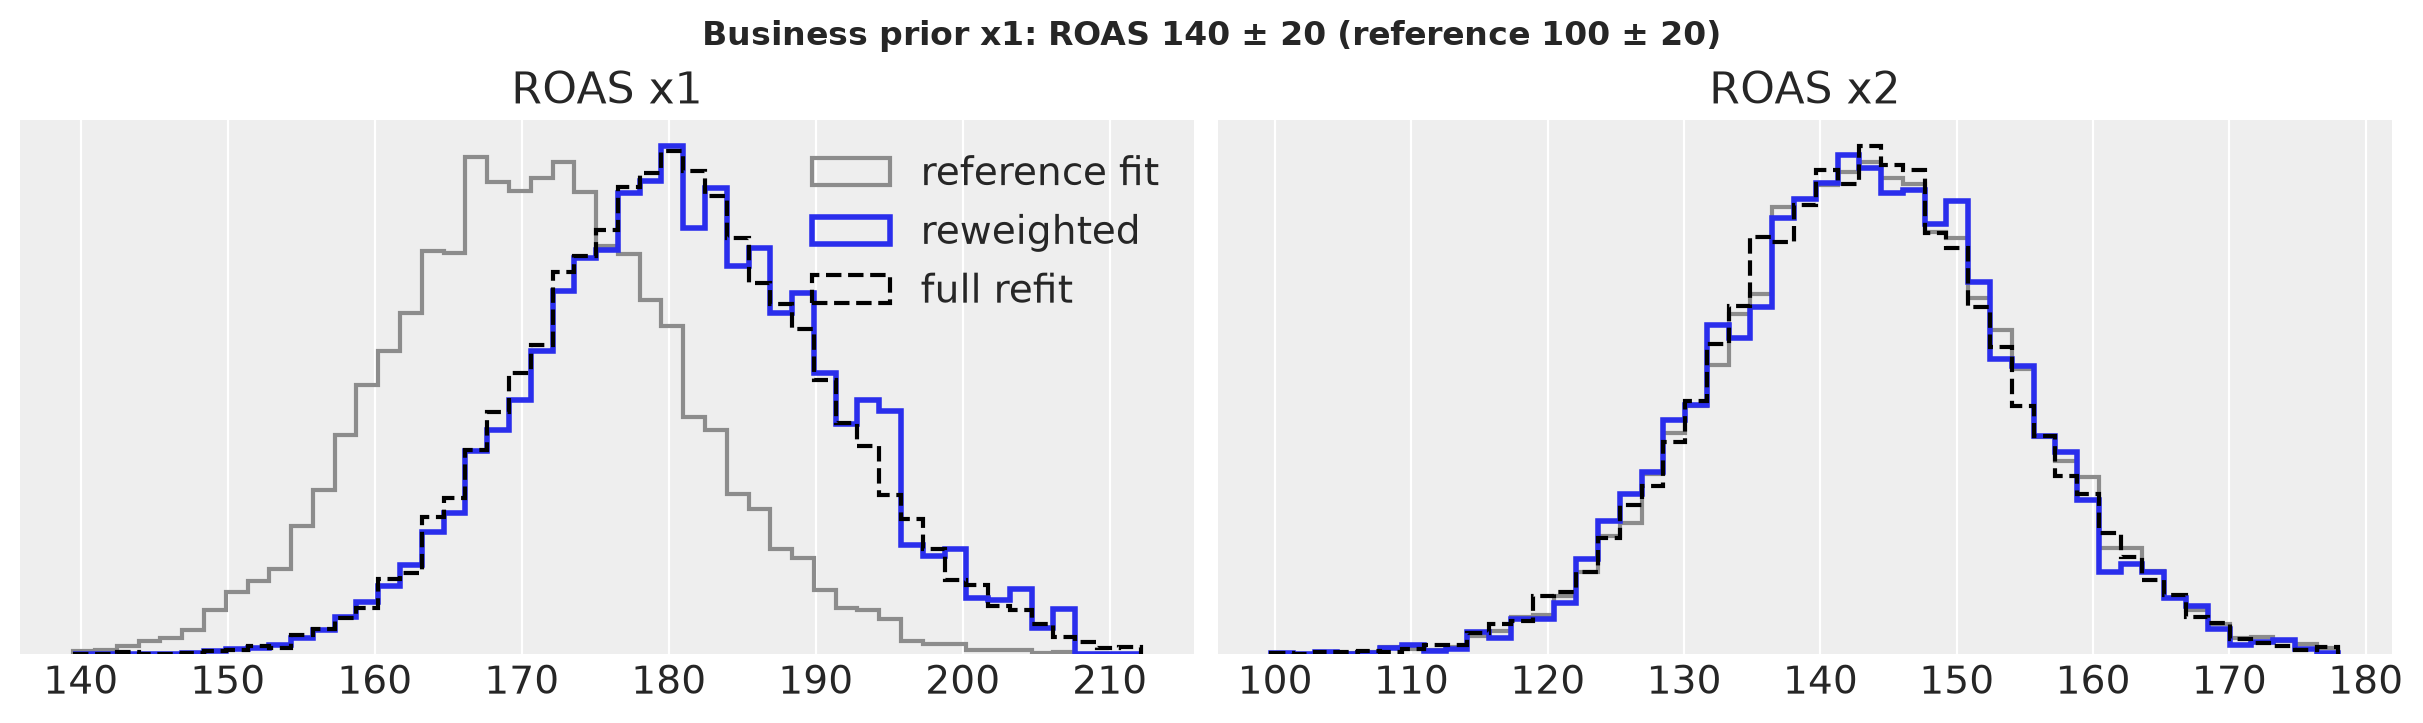

,reference,reweighted,reweighted sd,refit,refit sd,|reweighted - refit| / refit sd
channel,,,,,,
x1,170.92,180.93,10.13,180.49,10.12,0.04
x2,143.37,143.07,10.85,142.99,10.97,0.01


In [11]:
r_140, _ = try_spec(
    "Business prior x1: ROAS 140 ± 20 (reference 100 ± 20)",
    {"business": {"roas": [140.0, 150.0], "sigma": [20.0, 50.0]}},
    seed=2,
)

k̂ is below 0.5 and the reweighted posterior matches the refit. A prior-sensitivity analysis would have flagged x1 as sensitive; this gives the size of the shift (+10 ROAS, about one posterior SD) without a fit.

A much wider business prior is a bigger change for the weights: it asks for draws far from where the reference concentrated.

Business prior: sigma 2x wider (40 and 100)
reweighting took 0.003 s: k-hat = 0.55, ESS = 7% of the draws -> CHECK


Output()

full refit took 16 s


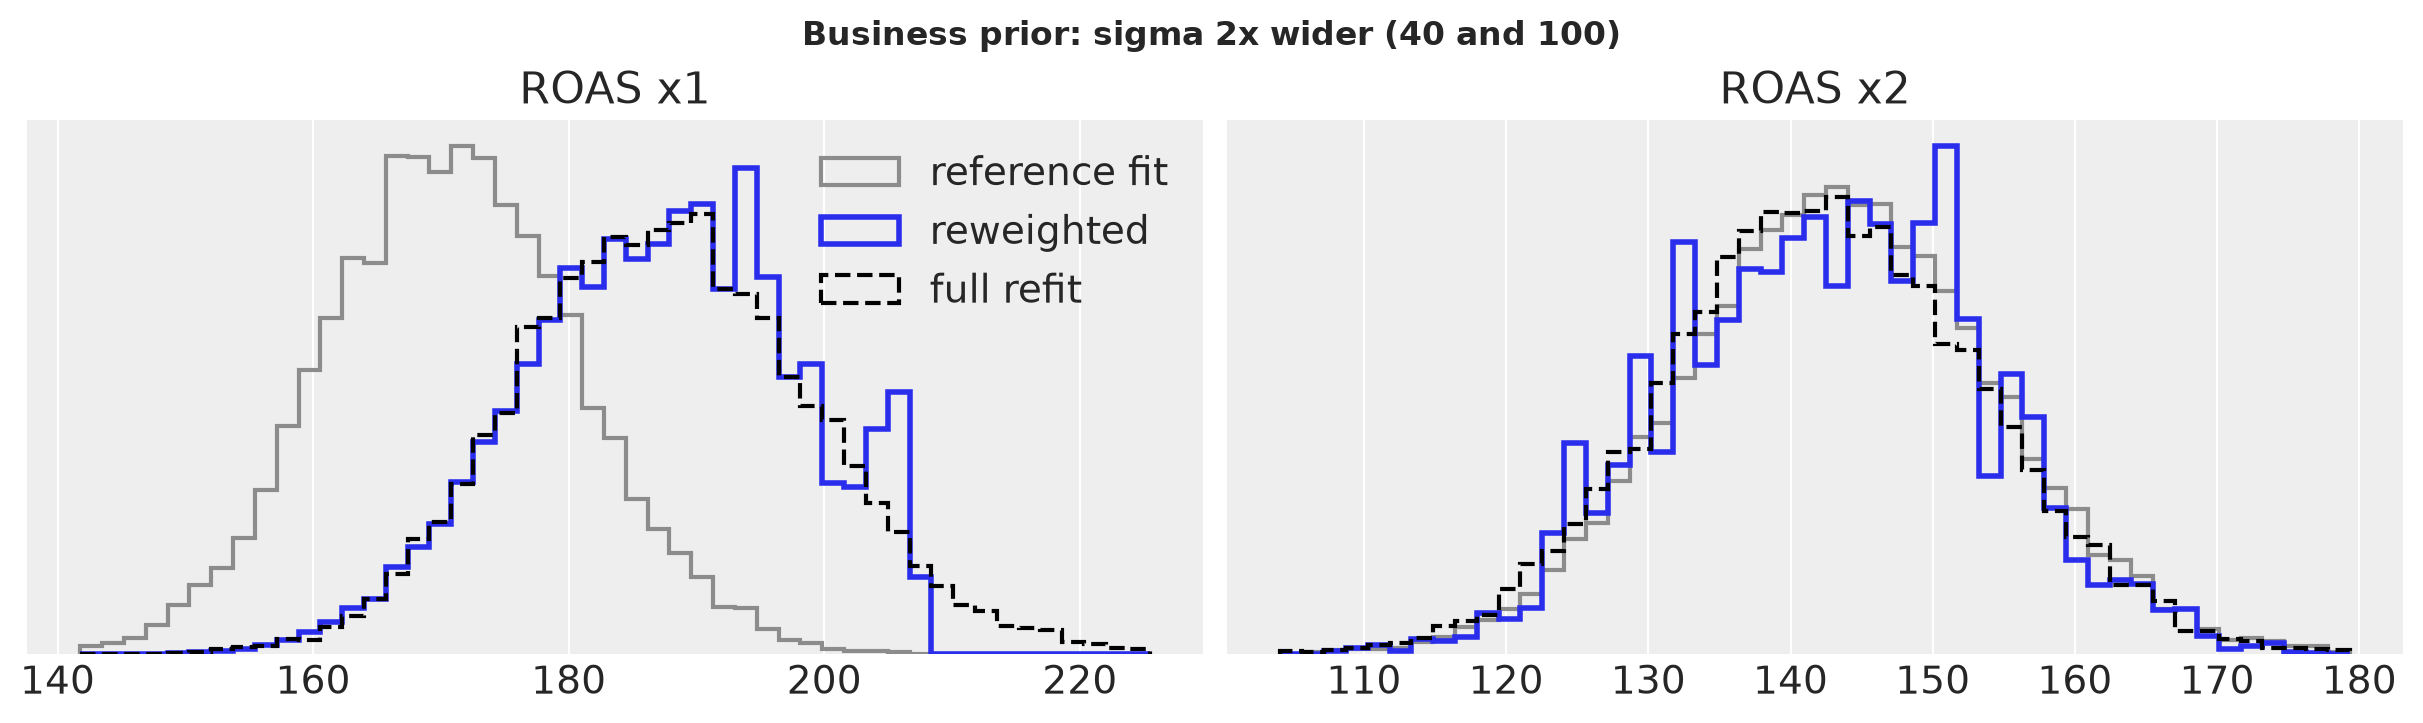

,reference,reweighted,reweighted sd,refit,refit sd,|reweighted - refit| / refit sd
channel,,,,,,
x1,170.92,187.09,10.72,187.52,11.57,0.04
x2,143.37,142.61,10.91,142.29,11.18,0.03


In [12]:
r_wide, _ = try_spec(
    "Business prior: sigma 2x wider (40 and 100)",
    {"business": {"roas": [100.0, 150.0], "sigma": [40.0, 100.0]}},
    seed=3,
)

k̂ is in the 0.5 – 0.7 band and the ESS is a few percent of the draws: **check**. Here the reweighted answer is within 0.1 refit SDs of the refit, but in the evidence (below) one scenario in ten in this band had a worst-quantity error above 0.36 refit SDs. If the number goes into a decision, refit.

## A Sensitivity Sweep With No Refits

The real use case: several candidate priors, one table. **refit** rows are priors the reference draws cannot answer; run a real fit for them. Their means are left out on purpose.

In [13]:
def sweep(candidates):
    """Reweight the reference draws to each candidate; one row per candidate, no refits."""
    rows = [
        {
            "change": "reference fit",
            "k-hat": np.nan,
            "ESS %": 100.0,
            "verdict": "-",
            **{f"ROAS {c}": roas[:, j].mean() for j, c in enumerate(channel_columns)},
        }
    ]
    for label, spec in candidates.items():
        result = psis_reweight(log_ratio(spec, ref), r_eff)
        means = result.weights @ roas if result.verdict != "refit" else [np.nan, np.nan]
        rows.append(
            {
                "change": label,
                "k-hat": result.pareto_k,
                "ESS %": 100 * result.ess_fraction,
                "verdict": result.verdict,
                **{f"ROAS {c}": means[j] for j, c in enumerate(channel_columns)},
            }
        )
    return pd.DataFrame(rows).set_index("change").round(2)

In [14]:
def business(roas, sigma):
    return {"business": {"roas": roas, "sigma": sigma}}


candidates = {
    "x1 target 60 (sigma 20)": business([60.0, 150.0], [20.0, 50.0]),
    "x1 target 130 (sigma 20)": business([130.0, 150.0], [20.0, 50.0]),
    "x1 target 140 (sigma 20)": business([140.0, 150.0], [20.0, 50.0]),
    "sigma 1.5x wider": business([100.0, 150.0], [30.0, 75.0]),
    "sigma 2x wider": business([100.0, 150.0], [40.0, 100.0]),
    "sigma 2x tighter": business([100.0, 150.0], [10.0, 25.0]),
    "saturation_beta HalfNormal(0.7)": {"sat_beta": 0.7},
    "saturation_beta HalfNormal(2)": {"sat_beta": 2.0},
    "adstock_alpha Beta(3, 3)": {"adstock": [3.0, 3.0]},
    "no business prior": {"business": "none"},
}
sweep(candidates)

,k-hat,ESS %,verdict,ROAS x1,ROAS x2
change,,,,,
reference fit,NaN,100.00,-,170.92,143.37
x1 target 60 (sigma 20),0.16,41.48,use it,161.68,143.72
x1 target 130 (sigma 20),0.16,56.56,use it,178.37,143.15
x1 target 140 (sigma 20),0.24,36.48,use it,180.93,143.07
sigma 1.5x wider,0.39,23.24,use it,182.36,142.84
sigma 2x wider,0.55,7.13,check,187.09,142.61
sigma 2x tighter,0.88,0.39,refit,NaN,NaN
saturation_beta HalfNormal(0.7),-0.25,61.07,use it,171.13,143.69
saturation_beta HalfNormal(2),0.64,5.15,check,170.98,142.73


The business prior is what moves x1. Moderate changes to it can be answered without a refit; tightening it pulls the posterior toward 100, where the reference has few draws, and needs one. The media priors tried here barely move ROAS (the data decide these); `saturation_beta` HalfNormal(2) is a bigger ask for the weights (k̂ in the check band).

## When Reweighting Cannot Help

Without the business prior the data alone leave x1 ROAS open: the sweep marks it **refit** (k̂ above 0.7, ESS 1 to 2%). The refit shows why.

No business prior
reweighting took 0.002 s: k-hat = 0.76, ESS = 2% of the draws -> REFIT


Output()

full refit took 14 s


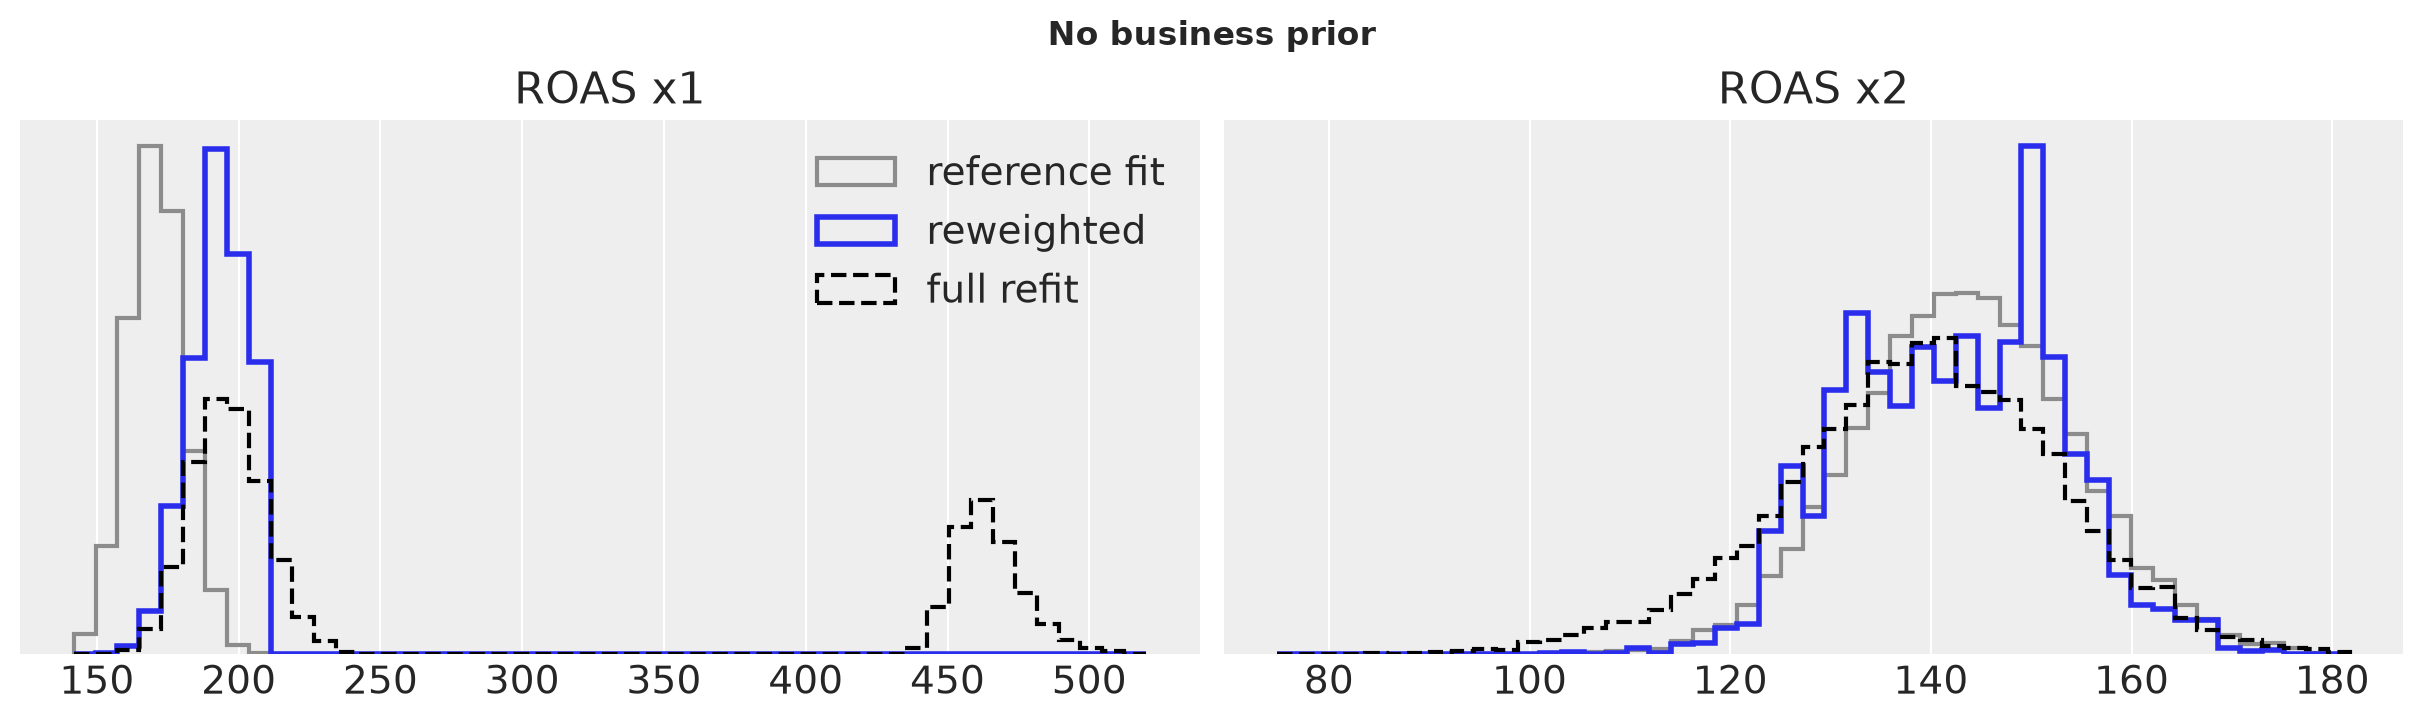

,reference,reweighted,reweighted sd,refit,refit sd,|reweighted - refit| / refit sd
channel,,,,,,
x1,170.92,192.94,9.84,285.95,127.33,0.73
x2,143.37,142.26,10.77,138.90,13.82,0.24


In [15]:
r_none, refit_none = try_spec("No business prior", {"business": "none"}, seed=4)

The reference draws live in one region of the posterior; weights cannot create draws in a region the reference never visited. Look at the refit chains:

In [16]:
posterior_none = refit_none.idata["posterior"]
print(
    "refit, x1 ROAS mean per chain:",
    posterior_none["ROAS"].sel(channel="x1").mean("draw").values.round(0),
)
print(
    "max r-hat of the refit:",
    round(float(az.rhat(posterior_none.to_dataset()[["ROAS"]])["ROAS"].max()), 2),
)

refit, x1 ROAS mean per chain: [196. 465. 196. 197. 465. 196.]
max r-hat of the refit: 1.61


The refit has two modes for x1 ROAS (the chains split between them, r̂ far above 1.01). The reference fit sits in one mode, so no reweighting can reach the other. k̂ flagged it before any refit did.

## Relation to Power-Scaling

The `az.psense` function of the sensitivity notebook reweights with `alpha`-powered priors or likelihoods, `log w = (alpha - 1) * log p`, for `alpha` within 1% of 1. That is the same computation with a small, fixed change. Here is the check for the business prior and the sales likelihood:

In [17]:
log_prior_business = ref.idata["log_prior"]["business_prior"].values.sum(
    -1
)  # (chain, draw)
log_lik_sales = ref.idata["log_likelihood"]["y"].values.sum(-1)
rows = []
for name, x in (
    ("business prior", log_prior_business),
    ("sales likelihood", log_lik_sales),
):
    for alpha in (0.99, 1.01):
        theirs = np.exp(array_stats.power_scale_lw(x, alpha=alpha, axis=(0, 1))).ravel()
        theirs /= theirs.sum()
        ours = psis_reweight(((alpha - 1) * x).ravel(), r_eff).weights
        rows.append(
            {
                "scaled term": name,
                "alpha": alpha,
                "ROAS x1 (power-scaling)": theirs @ roas[:, 0],
                "ROAS x1 (ours)": ours @ roas[:, 0],
            }
        )
pd.DataFrame(rows).round(3)

,scaled term,alpha,ROAS x1 (power-scaling),ROAS x1 (ours)
0,business prior,0.99,171.093,171.093
1,business prior,1.01,170.749,170.749
2,sales likelihood,0.99,170.751,170.751
3,sales likelihood,1.01,171.087,171.087


Same numbers. Power-scaling answers *is the posterior sensitive?* with a derivative at `alpha = 1`; reweighting answers *what would a specific different prior give?*, at finite distance, and says when the answer cannot be trusted.

## Limits

- **Only the prior changes.** Same data, model structure and likelihood; a different adstock or saturation function, new controls or more data need a refit. Likelihood changes are in {ref}`mmm_likelihood_reweighting`.
- **Support.** The new prior must put its mass where the reference prior does; the reference fit must have visited the region the new posterior lives in (see "When Reweighting Cannot Help").
- **k̂ is itself estimated from the draws.** For the same change it differs by up to 0.2 between this notebook's reference fit and the evidence's (sigma 2x wider: 0.55 vs 0.73). Treat 0.5 and 0.7 as zones, not lines; refit when a decision depends on a value near them.
- **k̂ is the main guide, the ESS the second.** Among scenarios with k̂ < 0.7, those with an ESS below 5% (6 scenarios) had a worst-quantity error of 0.23 refit SDs against 0.03 with an ESS above 20% (41 scenarios).

## Evidence

101 prior changes (business prior, `saturation_beta`, `adstock_alpha`, `saturation_lam`, `y_sigma`, and combinations), each reweighted from one reference fit and compared with a full refit of the same model. Errors are in refit posterior SDs; two refits of one scenario differ by 0.009. "Do nothing" is the unweighted reference posterior. Scenarios were selected to cover the k̂ range evenly, so the counts say nothing about how often a typical change is safe. Scripts, tables and figures are in the [evidence folder](https://github.com/hansamos/prior_sensitivity_pymc_marketing/tree/main/evidence).

| Pareto k̂ | scenarios | ESS (median) | error, worst quantity (median) | error, do nothing | closer than the reference |
|---|---|---|---|---|---|
| <0.3 | 20 | 95% | 0.027 | 0.23 | 100% of moved quantities |
| 0.3-0.5 | 20 | 41% | 0.043 | 0.67 | 100% of moved quantities |
| 0.5-0.7 | 20 | 8% | 0.084 | 1.2 | 99% of moved quantities |
| 0.7-1 | 19 | 1% | 0.24 | 1.7 | 96% of moved quantities |
| >=1 | 19 | 0% | 0.94 | 5.1 | 93% of moved quantities |

The table has 98 of the 101 scenarios. Three refits did not converge (the two-mode case above), so there is no reference answer for them; k̂ flagged all three (0.79 to 1.11).

## References

- Vehtari, A., Simpson, D., Gelman, A., Yao, Y., Gabry, J. (2024). Pareto smoothed importance sampling. *Journal of Machine Learning Research*, 25(72), 1-58. [jmlr.org/papers/v25/19-556](https://jmlr.org/papers/v25/19-556.html)
- Kallioinen, N., Paananen, T., Bürkner, P.-C., Vehtari, A. (2024). Detecting and diagnosing prior and likelihood sensitivity with power-scaling. *Statistics and Computing*, 34, 57. [doi:10.1007/s11222-023-10366-5](https://doi.org/10.1007/s11222-023-10366-5)
- {ref}`mmm_prior_sensitivity`: the model, the data and the power-scaling analysis used here.
- Companion notebook: {ref}`mmm_likelihood_reweighting`.

In [18]:
%load_ext watermark
%watermark -n -u -v -iv -w -p pymc_marketing,pytensor,nutpie

Last updated: Mon, 09 Nov 2026

Python implementation: CPython
Python version       : 3.12.16
IPython version      : 9.18.0

pymc_marketing: 1.3.0
pytensor      : 3.3.6
nutpie        : 0.16.11

IPython       : 9.18.0
arviz         : 1.3.0
logging       : 0.5.1.2
matplotlib    : 3.11.2
numpy         : 2.4.6
pandas        : 3.1.0
pymc          : 6.3.2
pymc_extras   : 0.15.1
pymc_marketing: 1.3.0
scipy         : 1.18.1

Watermark: 2.6.0

